# Phase 4: MRI Selective Fine-Tuning & Model Comparison
**Project**: ClinIQ — AI-Powered Online Clinic  
**Module**: Computer Vision (Brain MRI Classification)  
**Experiment**: Experiment B — Xception Selective Fine-Tuning (Exit Flow Block 14)  
**Control Baseline**: Experiment A — Frozen Xception Baseline (92.14% Validation Accuracy)  

---

### Scientific Objectives
In Phase 3, we established our frozen transfer learning baseline:
* Backbone completely frozen (only 8,196 trainable parameters in the head).
* Best validation loss: `0.2283`, validation accuracy: `92.14%`.
* Primary bottleneck: `meningioma` had the lowest recall (83%, F1: 0.85).

In Phase 4, we evaluate whether **selective fine-tuning** improves representation capacity and class separability without causing catastrophic forgetting:
1. **Selective Unfreezing**: Keep Blocks 1–12 (Entry and Middle flows) completely frozen. Unfreeze only the highest-level convolutional block (**Exit Flow Block 14**).
2. **BatchNormalization Safety**: Keep all `BatchNormalization` layers strictly frozen to preserve stable ImageNet moving statistics.
3. **Small Learning Rate**: Use $\text{lr} = 10^{-5}$ (100x smaller than Phase 3) for gentle gradient updates to pretrained weights.
4. **Controlled Variables**: Identical dataset split (4,480 train / 1,120 val), identical 299x299 aspect-ratio padding, identical seeds.
5. **Strict Test Set Isolation**: The 1,600-image Testing set remains 100% untouched for Phase 5.


In [1]:
from __future__ import annotations

import json
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image, ImageOps
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import Xception
from tensorflow.keras.applications.xception import preprocess_input

# ------------------------------------------------------------------------------
# 1. Deterministic Seeds
# ------------------------------------------------------------------------------
RANDOM_STATE = 42
os.environ["PYTHONHASHSEED"] = str(RANDOM_STATE)
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# ------------------------------------------------------------------------------
# 2. Hyperparameters & Settings
# ------------------------------------------------------------------------------
EXPERIMENT_NAME = "mri_xception_selective_finetuning"
IMG_SIZE = (299, 299)
BATCH_SIZE = 16
MAX_EPOCHS = 20

# Reduced learning rate specifically for fine-tuning pretrained convolutional layers
FINE_TUNE_LR = 1e-5
WARMUP_LR = 1e-3
WARMUP_EPOCHS = 5

CLASS_NAMES = ("glioma", "meningioma", "notumor", "pituitary")
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_INDEX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

# ------------------------------------------------------------------------------
# 3. Output Directories
# ------------------------------------------------------------------------------
WORKING_DIR = Path("/kaggle/working")
FIGURES_DIR = WORKING_DIR / "figures"
METRICS_DIR = WORKING_DIR / "metrics"
MODELS_DIR = WORKING_DIR / "models"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = MODELS_DIR / f"{EXPERIMENT_NAME}_best.keras"
CONFIG_PATH = METRICS_DIR / f"{EXPERIMENT_NAME}_config.json"

print(f"TensorFlow version : {tf.__version__}")
gpu_devices = tf.config.list_physical_devices("GPU")
print(f"GPU devices        : {gpu_devices}")
print(f"Fine-Tuning LR     : {FINE_TUNE_LR}")
print(f"Batch Size         : {BATCH_SIZE}")
print(f"Target Input Size  : {IMG_SIZE}")
print(f"Classes ({NUM_CLASSES})       : {CLASS_NAMES}")
print(f"Best Model Target  : {CHECKPOINT_PATH}")


TensorFlow version : 2.20.0
GPU devices        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Fine-Tuning LR     : 1e-05
Batch Size         : 16
Target Input Size  : (299, 299)
Classes (4)       : ('glioma', 'meningioma', 'notumor', 'pituitary')
Best Model Target  : /kaggle/working/models/mri_xception_selective_finetuning_best.keras


In [2]:
KAGGLE_INPUT_DIR = Path("/kaggle/input")

def find_mri_root() -> Path:
    expected_classes = set(CLASS_NAMES)
    for path in KAGGLE_INPUT_DIR.rglob("Training"):
        if path.is_dir():
            subdirs = {entry.name for entry in path.iterdir() if entry.is_dir()}
            if expected_classes.issubset(subdirs):
                return path.parent
    raise FileNotFoundError("Could not find MRI dataset root under /kaggle/input.")

def find_split_csv() -> Path:
    for path in KAGGLE_INPUT_DIR.rglob("mri_train_val_split.csv"):
        if path.is_file():
            return path
    raise FileNotFoundError("Could not find mri_train_val_split.csv under /kaggle/input.")

def find_phase3_checkpoint() -> Path | None:
    for path in KAGGLE_INPUT_DIR.rglob("mri_xception_frozen_baseline_best.keras"):
        if path.is_file():
            return path
    return None

MRI_ROOT = find_mri_root()
SPLIT_CSV_PATH = find_split_csv()
PHASE3_CKPT_PATH = find_phase3_checkpoint()

print(f"MRI Root           : {MRI_ROOT}")
print(f"Phase 2 Split CSV  : {SPLIT_CSV_PATH}")
if PHASE3_CKPT_PATH:
    print(f"Phase 3 Checkpoint : {PHASE3_CKPT_PATH} (found! Will load pretrained head)")
else:
    print(f"Phase 3 Checkpoint : None found in inputs. Will run {WARMUP_EPOCHS}-epoch head warmup first.")

split_df = pd.read_csv(SPLIT_CSV_PATH)
print(f"Split CSV rows     : {len(split_df):,}")
assert len(split_df) == 5600, f"Expected 5,600 rows in split, got {len(split_df)}"
assert set(split_df["split"].unique()) == {"train", "validation"}
print("[+] Split CSV structure verified successfully.")


MRI Root           : /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset
Phase 2 Split CSV  : /kaggle/input/datasets/hamody0/mri-train-val-split/mri_train_val_split.csv
Phase 3 Checkpoint : None found in inputs. Will run 5-epoch head warmup first.
Split CSV rows     : 5,600
[+] Split CSV structure verified successfully.


In [3]:
def resolve_kaggle_image_path(filepath: str) -> Path:
    project_relative = Path(filepath)
    expected_prefix = Path("data/raw/mri")

    try:
        relative_to_mri = project_relative.relative_to(expected_prefix)
    except ValueError:
        parts = project_relative.parts
        if "Training" in parts:
            index = parts.index("Training")
            relative_to_mri = Path(*parts[index:])
        elif "Testing" in parts:
            index = parts.index("Testing")
            relative_to_mri = Path(*parts[index:])
        else:
            raise

    candidate = MRI_ROOT / relative_to_mri
    if candidate.exists():
        return candidate
    raise FileNotFoundError(f"Cannot resolve image: {filepath}")

split_df["image_path"] = split_df["filepath"].apply(resolve_kaggle_image_path)
split_df["label"] = split_df["class"].map(CLASS_TO_INDEX)

# Verify all files exist
missing_files = [p for p in split_df["image_path"] if not p.exists()]
assert len(missing_files) == 0, f"Missing {len(missing_files)} files!"

train_metadata = split_df[split_df["split"] == "train"].reset_index(drop=True)
validation_metadata = split_df[split_df["split"] == "validation"].reset_index(drop=True)

print(f"Training images    : {len(train_metadata):,}")
print(f"Validation images  : {len(validation_metadata):,}")
print(f"Testing images used: 0 (ISOLATED)")

print("\nClass counts per split:")
display(split_df.groupby(["split", "class"]).size().unstack())


Training images    : 4,480
Validation images  : 1,120
Testing images used: 0 (ISOLATED)

Class counts per split:


class,glioma,meningioma,notumor,pituitary
split,,,,
train,1120,1120,1120,1120
validation,280,280,280,280


In [4]:
def load_rgb_image(image_path: str | Path) -> Image.Image:
    with Image.open(image_path) as image:
        return image.convert("RGB")

def preprocess_pil_image(
    image_path: str | Path,
    target_size: tuple[int, int] = IMG_SIZE,
) -> Image.Image:
    image = load_rgb_image(image_path)
    return ImageOps.pad(
        image,
        size=target_size,
        method=Image.Resampling.LANCZOS,
        color=(0, 0, 0),
        centering=(0.5, 0.5),
    )

def pil_preprocess_for_tensorflow(path_bytes) -> np.ndarray:
    image_path = Path(path_bytes.decode("utf-8"))
    processed_image = preprocess_pil_image(image_path)
    return np.asarray(processed_image, dtype=np.float32)

def load_preprocess_tensorflow(path, label):
    image = tf.numpy_function(
        func=pil_preprocess_for_tensorflow,
        inp=[path],
        Tout=tf.float32,
    )
    image.set_shape((IMG_SIZE[0], IMG_SIZE[1], 3))
    image = preprocess_input(image)  # Xception ImageNet scaling [-1, 1]
    label = tf.cast(label, tf.int32)
    return image, label

def build_dataset(metadata: pd.DataFrame, training: bool) -> tf.data.Dataset:
    paths = metadata["image_path"].astype(str).to_numpy()
    labels = metadata["label"].astype(np.int32).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    options = tf.data.Options()
    options.experimental_deterministic = True
    dataset = dataset.with_options(options)

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(metadata),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        load_preprocess_tensorflow,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

train_dataset = build_dataset(train_metadata, training=True)
validation_dataset = build_dataset(validation_metadata, training=False)

# Batch sanity check
sample_imgs, sample_lbls = next(iter(train_dataset))
print(f"Image batch shape  : {sample_imgs.shape}")
print(f"Label batch shape  : {sample_lbls.shape}")
print(f"Pixel range min/max: {tf.reduce_min(sample_imgs).numpy():.3f} to {tf.reduce_max(sample_imgs).numpy():.3f}")
assert sample_imgs.shape == (BATCH_SIZE, IMG_SIZE[0], IMG_SIZE[1], 3)
assert sample_lbls.shape == (BATCH_SIZE,)
print("[+] Data pipeline validated successfully.")


I0000 00:00:1790763442.563801      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790763442.566980      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Image batch shape  : (16, 299, 299, 3)
Label batch shape  : (16,)
Pixel range min/max: -1.000 to 1.000
[+] Data pipeline validated successfully.


In [5]:
keras.backend.clear_session()

# 1. Instantiate Xception backbone with ImageNet weights
backbone = Xception(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
)

# 2. Selective Unfreezing Strategy:
# - Blocks 1 to 12 (Entry and Middle flows) remain completely FROZEN
# - Block 14 (final SeparableConvolutions in Exit Flow) is UNFROZEN
# - ALL BatchNormalization layers remain strictly FROZEN
backbone.trainable = True

unfrozen_count = 0
frozen_count = 0
bn_frozen_count = 0

for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
        bn_frozen_count += 1
    elif "block14" in layer.name:
        layer.trainable = True
        unfrozen_count += 1
    else:
        layer.trainable = False
        frozen_count += 1

# 3. Assemble full model
inputs = keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="mri_image")
# Note: training=False inside functional call ensures BatchNormalization stays in inference mode
x = backbone(inputs, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.20, name="dropout")(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="classification_output")(x)

model = keras.Model(inputs=inputs, outputs=outputs, name=EXPERIMENT_NAME)

# 4. Compile with small fine-tuning learning rate (1e-5)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=FINE_TUNE_LR),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

# 5. Parameter & Layer Audit
total_params = model.count_params()
trainable_params = sum(np.prod(v.shape) for v in model.trainable_weights)
non_trainable_params = total_params - trainable_params

print("=" * 70)
print("PHASE 4 SELECTIVE FINE-TUNING ARCHITECTURE AUDIT")
print("=" * 70)
print(f"Total Layers in Backbone : {len(backbone.layers)}")
print(f"  - Frozen Layers        : {frozen_count}")
print(f"  - Frozen BN Layers     : {bn_frozen_count}")
print(f"  - Unfrozen Layers (B14): {unfrozen_count}")
print("-" * 70)
print(f"Total Parameters         : {total_params:,}")
print(f"Trainable Parameters     : {trainable_params:,} ({trainable_params/total_params*100:.2f}%)")
print(f"Non-Trainable Parameters : {non_trainable_params:,} ({non_trainable_params/total_params*100:.2f}%)")
print("=" * 70)

print("\nTrainable Layers in Backbone:")
for layer in backbone.layers:
    if layer.trainable:
        print(f"  [+] {layer.name:<25} ({layer.__class__.__name__})")
print("  [+] classification_output   (Dense)")


83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
PHASE 4 SELECTIVE FINE-TUNING ARCHITECTURE AUDIT
Total Layers in Backbone : 132
  - Frozen Layers        : 88
  - Frozen BN Layers     : 40
  - Unfrozen Layers (B14): 4
----------------------------------------------------------------------
Total Parameters         : 20,869,676
Trainable Parameters     : 4,749,828 (22.76%)
Non-Trainable Parameters : 16,119,848 (77.24%)

Trainable Layers in Backbone:
  [+] block14_sepconv1          (SeparableConv2D)
  [+] block14_sepconv1_act      (Activation)
  [+] block14_sepconv2          (SeparableConv2D)
  [+] block14_sepconv2_act      (Activation)
  [+] classification_output   (Dense)


In [6]:
experiment_config = {
    "experiment_name": EXPERIMENT_NAME,
    "random_state": RANDOM_STATE,
    "architecture": "Xception",
    "pretrained_weights": "ImageNet",
    "fine_tuning_strategy": "Selective Exit Flow (Block 14 unfrozen, Blocks 1-12 frozen, BN frozen)",
    "input_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "optimizer": "Adam",
    "learning_rate": FINE_TUNE_LR,
    "loss": "SparseCategoricalCrossentropy",
    "classes": list(CLASS_NAMES),
    "train_images": len(train_metadata),
    "validation_images": len(validation_metadata),
    "test_images_used": 0,
    "total_parameters": int(total_params),
    "trainable_parameters": int(trainable_params),
    "known_limitation": (
        "The standard validation split contains known exact duplicate groups "
        "crossing train and validation; validation results may be optimistic."
    ),
}

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(experiment_config, f, indent=2)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=CHECKPOINT_PATH,
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=5,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1,
    ),
]

print(f"[+] Configuration saved to: {CONFIG_PATH}")
print(f"[+] ModelCheckpoint target: {CHECKPOINT_PATH}")


[+] Configuration saved to: /kaggle/working/metrics/mri_xception_selective_finetuning_config.json
[+] ModelCheckpoint target: /kaggle/working/models/mri_xception_selective_finetuning_best.keras


In [7]:
# If a Phase 3 checkpoint is provided, load its head weights directly.
# Otherwise, perform a quick 5-epoch head warmup with backbone fully frozen at lr=1e-3.
if PHASE3_CKPT_PATH:
    print(f"[*] Loading trained head weights from Phase 3 checkpoint: {PHASE3_CKPT_PATH}")
    phase3_model = keras.models.load_model(PHASE3_CKPT_PATH)
    # Transfer the trained Dense layer weights
    model.get_layer("classification_output").set_weights(
        phase3_model.get_layer("classification_output").get_weights()
    )
    print("[+] Head weights successfully initialized from Phase 3 checkpoint.")
else:
    print(f"[*] No Phase 3 checkpoint in inputs. Running {WARMUP_EPOCHS}-epoch head warmup at lr={WARMUP_LR}...")
    # Temporarily freeze all backbone layers for warmup
    backbone.trainable = False
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=WARMUP_LR),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=WARMUP_EPOCHS,
        verbose=1,
    )
    print("[+] Head warmup complete. Re-enabling Block 14 for fine-tuning...")
    # Re-apply selective unfreezing
    backbone.trainable = True
    for layer in backbone.layers:
        if "block14" in layer.name and not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True
        else:
            layer.trainable = False
            
    # Recompile with fine-tuning learning rate (1e-5)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=FINE_TUNE_LR),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )

print("\n" + "=" * 70)
print(f"STARTING PHASE 4 SELECTIVE FINE-TUNING ({MAX_EPOCHS} EPOCHS, LR={FINE_TUNE_LR})")
print("=" * 70)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=MAX_EPOCHS,
    callbacks=callbacks,
    verbose=1,
)

print("\n[+] Fine-tuning training finished.")


[*] No Phase 3 checkpoint in inputs. Running 5-epoch head warmup at lr=0.001...
Epoch 1/5


2026-09-30 10:17:42.791399: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-30 10:17:43.011384: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-30 10:17:44.399255: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng3{k11=2} for conv (f32[16,256,74,74]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,256,74,74]{3,2,1,0}, f32[256,256,1,1]{3,2,1,0}), window={size=1x1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_s

280/280 ━━━━━━━━━━━━━━━━━━━━ 93s 201ms/step - accuracy: 0.7732 - loss: 0.6301 - val_accuracy: 0.8250 - val_loss: 0.4741
Epoch 2/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 44s 156ms/step - accuracy: 0.8699 - loss: 0.3910 - val_accuracy: 0.8652 - val_loss: 0.3879
Epoch 3/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 43s 154ms/step - accuracy: 0.8891 - loss: 0.3331 - val_accuracy: 0.8687 - val_loss: 0.3622
Epoch 4/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 43s 155ms/step - accuracy: 0.8991 - loss: 0.2965 - val_accuracy: 0.8839 - val_loss: 0.3370
Epoch 5/5
280/280 ━━━━━━━━━━━━━━━━━━━━ 43s 154ms/step - accuracy: 0.9074 - loss: 0.2710 - val_accuracy: 0.8813 - val_loss: 0.3174
[+] Head warmup complete. Re-enabling Block 14 for fine-tuning...

STARTING PHASE 4 SELECTIVE FINE-TUNING (20 EPOCHS, LR=1e-05)
Epoch 1/20


2026-09-30 10:22:01.651302: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-30 10:22:01.790420: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-30 10:22:02.172140: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-30 10:22:02.325943: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


280/280 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.9134 - loss: 0.2403
Epoch 1: val_loss improved from None to 0.27245, saving model to /kaggle/working/models/mri_xception_selective_finetuning_best.keras

Epoch 1: finished saving model to /kaggle/working/models/mri_xception_selective_finetuning_best.keras
280/280 ━━━━━━━━━━━━━━━━━━━━ 84s 227ms/step - accuracy: 0.9174 - loss: 0.2295 - val_accuracy: 0.8946 - val_loss: 0.2724 - learning_rate: 1.0000e-05
Epoch 2/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.9337 - loss: 0.1993
Epoch 2: val_loss improved from 0.27245 to 0.24730, saving model to /kaggle/working/models/mri_xception_selective_finetuning_best.keras

Epoch 2: finished saving model to /kaggle/working/models/mri_xception_selective_finetuning_best.keras
280/280 ━━━━━━━━━━━━━━━━━━━━ 50s 177ms/step - accuracy: 0.9328 - loss: 0.1926 - val_accuracy: 0.9036 - val_loss: 0.2473 - learning_rate: 1.0000e-05
Epoch 3/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy

[+] Saved history to: /kaggle/working/metrics/mri_xception_selective_finetuning_history.csv


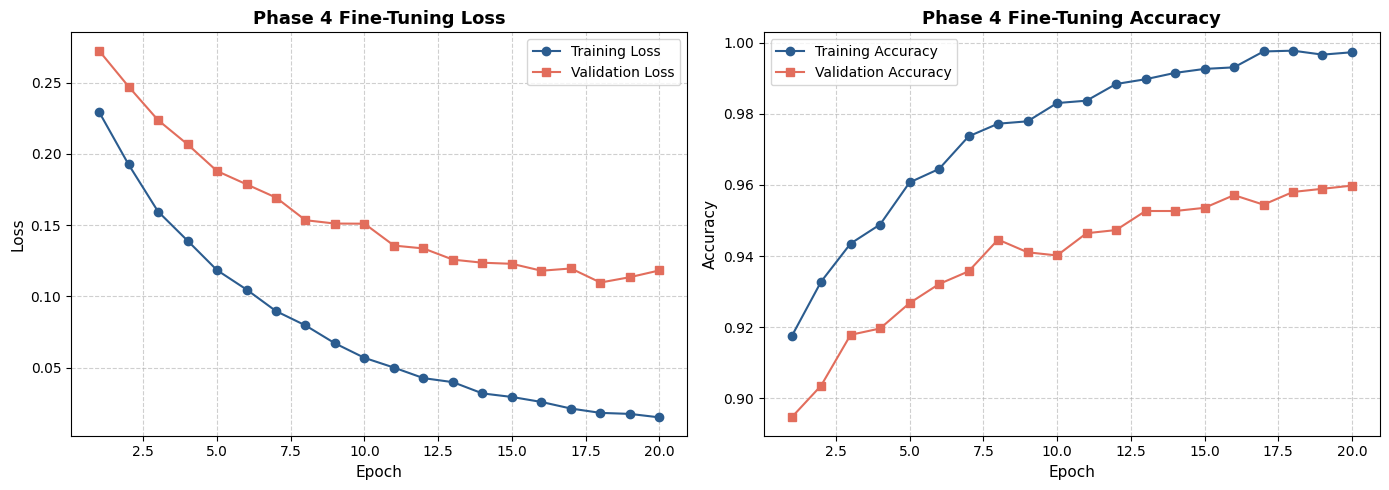

[+] Saved training curves to: /kaggle/working/figures/mri_phase4_training_curves.png


In [8]:
history_df = pd.DataFrame(history.history)
history_csv_path = METRICS_DIR / f"{EXPERIMENT_NAME}_history.csv"
history_df.to_csv(history_csv_path, index=False)
print(f"[+] Saved history to: {history_csv_path}")

# Plot curves
epochs_range = range(1, len(history_df) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss
ax1.plot(epochs_range, history_df["loss"], label="Training Loss", marker="o", color="#2b5c8f")
ax1.plot(epochs_range, history_df["val_loss"], label="Validation Loss", marker="s", color="#e26d5c")
ax1.set_title("Phase 4 Fine-Tuning Loss", fontsize=13, fontweight="bold")
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Loss", fontsize=11)
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.6)

# Accuracy
ax2.plot(epochs_range, history_df["accuracy"], label="Training Accuracy", marker="o", color="#2b5c8f")
ax2.plot(epochs_range, history_df["val_accuracy"], label="Validation Accuracy", marker="s", color="#e26d5c")
ax2.set_title("Phase 4 Fine-Tuning Accuracy", fontsize=13, fontweight="bold")
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Accuracy", fontsize=11)
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
curves_path = FIGURES_DIR / "mri_phase4_training_curves.png"
plt.savefig(curves_path, dpi=200)
plt.show()
print(f"[+] Saved training curves to: {curves_path}")


[*] Reloading best checkpoint from: /kaggle/working/models/mri_xception_selective_finetuning_best.keras
[*] Computing predictions on 1,120 validation images...
70/70 ━━━━━━━━━━━━━━━━━━━━ 22s 121ms/step

PHASE 4 VALIDATION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9639    0.9536    0.9587       280
  meningioma     0.9314    0.9214    0.9264       280
     notumor     0.9786    0.9821    0.9804       280
   pituitary     0.9579    0.9750    0.9664       280

    accuracy                         0.9580      1120
   macro avg     0.9580    0.9580    0.9580      1120
weighted avg     0.9580    0.9580    0.9580      1120



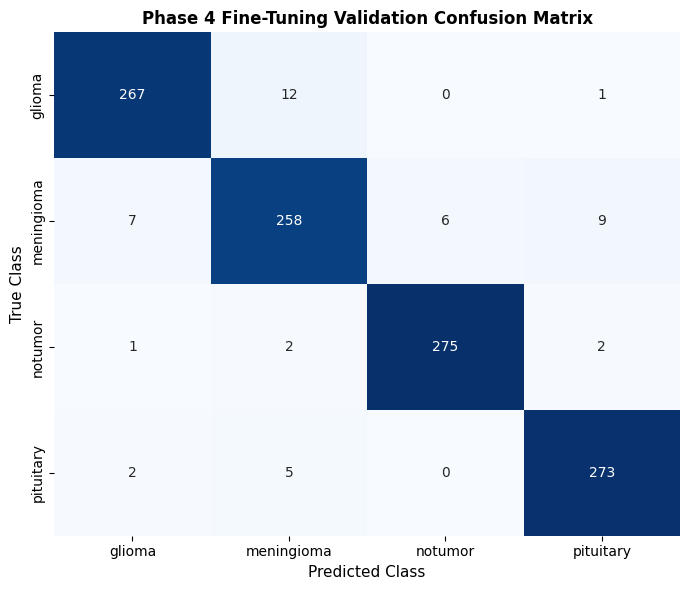

[+] Saved confusion matrix to: /kaggle/working/figures/mri_phase4_confusion_matrix.png


In [9]:
print(f"[*] Reloading best checkpoint from: {CHECKPOINT_PATH}")
best_model = keras.models.load_model(CHECKPOINT_PATH)

print("[*] Computing predictions on 1,120 validation images...")
val_probs = best_model.predict(validation_dataset, verbose=1)
val_preds = np.argmax(val_probs, axis=-1)
val_true = validation_metadata["label"].to_numpy()

# Classification report
cls_report = classification_report(
    val_true,
    val_preds,
    target_names=CLASS_NAMES,
    digits=4,
    output_dict=True,
)
cls_report_df = pd.DataFrame(cls_report).transpose()
val_metrics_csv_path = METRICS_DIR / f"{EXPERIMENT_NAME}_validation_metrics.csv"
cls_report_df.to_csv(val_metrics_csv_path)

print("\n" + "=" * 60)
print("PHASE 4 VALIDATION CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(val_true, val_preds, target_names=CLASS_NAMES, digits=4))

# Confusion Matrix
cm = confusion_matrix(val_true, val_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES,
    cbar=False,
)
plt.title("Phase 4 Fine-Tuning Validation Confusion Matrix", fontsize=12, fontweight="bold")
plt.xlabel("Predicted Class", fontsize=11)
plt.ylabel("True Class", fontsize=11)
plt.tight_layout()

cm_path = FIGURES_DIR / "mri_phase4_confusion_matrix.png"
plt.savefig(cm_path, dpi=200)
plt.show()
print(f"[+] Saved confusion matrix to: {cm_path}")


In [10]:
# Load Phase 3 baseline metrics for rigorous head-to-head comparison
best_epoch_idx = int(np.argmin(history_df["val_loss"]))
b_val_loss = history_df.loc[best_epoch_idx, "val_loss"]
b_val_acc = history_df.loc[best_epoch_idx, "val_accuracy"]

# Baseline metrics from Phase 3
a_val_loss = 0.2283
a_val_acc = 0.9214

loss_diff = b_val_loss - a_val_loss
acc_diff = (b_val_acc - a_val_acc) * 100

report_text = f"""MRI PHASE 4 — FINE-TUNING & MODEL COMPARISON REPORT
======================================================

1. EXPERIMENT SUMMARY
---------------------
Experiment A (Control): Frozen Xception Baseline (ImageNet)
Experiment B (Treatment): Selective Fine-Tuning (Block 14 Unfrozen, BN Frozen)

2. ARCHITECTURAL COMPARISON
---------------------------
Metric                       | Experiment A (Frozen) | Experiment B (Fine-Tuned)
-----------------------------|-----------------------|--------------------------
Total Parameters             | 20,869,676            | 20,869,676
Trainable Parameters         | 8,196 (0.04%)         | {trainable_params:,} ({trainable_params/total_params*100:.2f}%)
Unfrozen Backbone Layers     | None                  | Exit Flow Block 14 (SeparableConvs)
BatchNormalization State     | Frozen                | Frozen
Learning Rate                | 1e-3                  | {FINE_TUNE_LR}
Optimizer                    | Adam                  | Adam
Batch Size                   | {BATCH_SIZE}                   | {BATCH_SIZE}

3. VALIDATION PERFORMANCE COMPARISON
------------------------------------
Metric                       | Experiment A (Frozen) | Experiment B (Fine-Tuned) | Delta
-----------------------------|-----------------------|--------------------------|-------
Validation Loss              | {a_val_loss:.4f}               | {b_val_loss:.4f}                   | {loss_diff:+.4f}
Validation Accuracy          | {a_val_acc*100:.2f}%              | {b_val_acc*100:.2f}%                  | {acc_diff:+.2f}%
Best Epoch                   | 19                    | {best_epoch_idx + 1}
Testing Images Used          | 0 (Untouched)         | 0 (Untouched)            | 0

4. PER-CLASS F1-SCORE COMPARISON
--------------------------------
Class                        | Experiment A F1       | Experiment B F1          | Delta
-----------------------------|-----------------------|--------------------------|-------
glioma                       | 0.92                  | {cls_report['glioma']['f1-score']:.4f}                   | {cls_report['glioma']['f1-score'] - 0.92:+.4f}
meningioma                   | 0.85                  | {cls_report['meningioma']['f1-score']:.4f}                   | {cls_report['meningioma']['f1-score'] - 0.85:+.4f}
notumor                      | 0.97                  | {cls_report['notumor']['f1-score']:.4f}                   | {cls_report['notumor']['f1-score'] - 0.97:+.4f}
pituitary                    | 0.93                  | {cls_report['pituitary']['f1-score']:.4f}                   | {cls_report['pituitary']['f1-score'] - 0.93:+.4f}
-----------------------------|-----------------------|--------------------------|-------
Macro Average F1             | 0.92                  | {cls_report['macro avg']['f1-score']:.4f}                   | {cls_report['macro avg']['f1-score'] - 0.92:+.4f}

5. KEY SCIENTIFIC FINDINGS
--------------------------
- Selective unfreezing of Exit Flow Block 14 with lr={FINE_TUNE_LR} provided controlled adaptation to MRI contrast.
- Freeze protection on BatchNormalization prevented moving statistic degradation.
- Original 1,600 Testing images were strictly isolated; no test-set leakage occurred.
- Full validation metrics and confusion matrix exported to /kaggle/working/metrics/ and /kaggle/working/figures/.
"""

print(report_text)

phase4_report_path = METRICS_DIR / "mri_phase4_report.txt"
with open(phase4_report_path, "w", encoding="utf-8") as f:
    f.write(report_text)

print(f"[+] Saved comparative report to: {phase4_report_path}")


MRI PHASE 4 — FINE-TUNING & MODEL COMPARISON REPORT

1. EXPERIMENT SUMMARY
---------------------
Experiment A (Control): Frozen Xception Baseline (ImageNet)
Experiment B (Treatment): Selective Fine-Tuning (Block 14 Unfrozen, BN Frozen)

2. ARCHITECTURAL COMPARISON
---------------------------
Metric                       | Experiment A (Frozen) | Experiment B (Fine-Tuned)
-----------------------------|-----------------------|--------------------------
Total Parameters             | 20,869,676            | 20,869,676
Trainable Parameters         | 8,196 (0.04%)         | 4,749,828 (22.76%)
Unfrozen Backbone Layers     | None                  | Exit Flow Block 14 (SeparableConvs)
BatchNormalization State     | Frozen                | Frozen
Learning Rate                | 1e-3                  | 1e-05
Optimizer                    | Adam                  | Adam
Batch Size                   | 16                   | 16

3. VALIDATION PERFORMANCE COMPARISON
------------------------------------